# Estimation of Obesity Levels Based On Eating Habits and Physical Condition
Dataset available at https://archive.ics.uci.edu/dataset/544/estimation+of+obesity+levels+based+on+eating+habits+and+physical+condition

In [1]:
#Importing the libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#Reading the dataset
df = pd.read_csv('ObesityDataSet_raw_and_data_sinthetic.csv')

In [3]:
#Using just the raw material and excluding the data generating by SMOTE
df_raw = df.iloc[:498].copy()

# 1.      Summarize your dataset clearly, using relevant descriptive statistics and appropriate plots. These should be carefully motivated and justified and clearly presented. You should critically analyse your findings, in addition to including the necessary Python code, output and plots in the report. You are required to plot at least three graphs. 

In [4]:
#Using head and tail to have a look at the data
df_raw.head(10)

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II
5,Male,29.0,1.62,53.0,no,yes,2.0,3.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Automobile,Normal_Weight
6,Female,23.0,1.50,55.0,yes,yes,3.0,3.0,Sometimes,no,2.0,no,1.0,0.0,Sometimes,Motorbike,Normal_Weight
7,Male,22.0,1.64,53.0,no,no,2.0,3.0,Sometimes,no,2.0,no,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
8,Male,24.0,1.78,64.0,yes,yes,3.0,3.0,Sometimes,no,2.0,no,1.0,1.0,Frequently,Public_Transportation,Normal_Weight
9,Male,22.0,1.72,68.0,yes,yes,2.0,3.0,Sometimes,no,2.0,no,1.0,1.0,no,Public_Transportation,Normal_Weight


In [5]:
df_raw.tail(10)

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
488,Male,21.0,1.88,84.0,yes,yes,3.0,3.0,Sometimes,no,3.0,no,2.0,1.0,Sometimes,Walking,Normal_Weight
489,Female,19.0,1.56,50.0,no,yes,2.0,1.0,Sometimes,no,1.0,no,0.0,2.0,no,Public_Transportation,Normal_Weight
490,Male,24.0,1.75,84.0,no,yes,3.0,3.0,no,no,2.0,yes,1.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II
491,Male,25.0,1.66,68.0,no,yes,2.0,3.0,Sometimes,yes,1.0,no,1.0,1.0,Sometimes,Public_Transportation,Normal_Weight
492,Male,45.0,1.70,86.0,no,yes,3.0,3.0,Frequently,no,1.0,no,0.0,0.0,no,Automobile,Overweight_Level_II
493,Male,20.0,1.80,65.0,no,yes,2.0,3.0,Frequently,no,1.0,no,2.0,0.0,Sometimes,Motorbike,Normal_Weight
494,Female,18.0,1.67,66.0,no,yes,3.0,3.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Normal_Weight
495,Male,19.0,1.80,60.0,yes,yes,3.0,1.0,Always,no,1.0,yes,0.0,0.0,no,Motorbike,Normal_Weight
496,Male,18.0,1.72,53.0,yes,yes,2.0,3.0,Sometimes,no,2.0,no,0.0,2.0,Sometimes,Public_Transportation,Insufficient_Weight
497,Male,20.0,1.56,45.0,no,no,2.0,3.0,Sometimes,no,2.0,no,1.0,1.0,Sometimes,Public_Transportation,Normal_Weight


In [6]:
#Checking the shape of the data
df_raw.shape

(498, 17)

In [7]:
#Checking the possible outputs of the variables using "unique"
df_raw['Gender'].unique()

array(['Female', 'Male'], dtype=object)

In [8]:
df_raw['family_history_with_overweight'].unique()

array(['yes', 'no'], dtype=object)

In [9]:
df_raw['FAVC'].unique()

array(['no', 'yes'], dtype=object)

In [10]:
df_raw['FCVC'].unique()

array([2., 3., 1.])

In [11]:
df_raw['NCP'].unique()

array([3., 1., 4.])

In [12]:
df_raw['CAEC'].unique()

array(['Sometimes', 'Frequently', 'Always', 'no'], dtype=object)

In [13]:
df_raw['CH2O'].unique()

array([2., 3., 1.])

In [14]:
df_raw['SCC'].unique()

array(['no', 'yes'], dtype=object)

In [15]:
#Checking the dataset with info function to check the category of all the columns and if there is some missing values
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 498 entries, 0 to 497
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Gender                          498 non-null    object 
 1   Age                             498 non-null    float64
 2   Height                          498 non-null    float64
 3   Weight                          498 non-null    float64
 4   family_history_with_overweight  498 non-null    object 
 5   FAVC                            498 non-null    object 
 6   FCVC                            498 non-null    float64
 7   NCP                             498 non-null    float64
 8   CAEC                            498 non-null    object 
 9   SMOKE                           498 non-null    object 
 10  CH2O                            498 non-null    float64
 11  SCC                             498 non-null    object 
 12  FAF                             498 

In [16]:
# Double check missing values with isnull function
df_raw.isnull().sum()

Gender                            0
Age                               0
Height                            0
Weight                            0
family_history_with_overweight    0
FAVC                              0
FCVC                              0
NCP                               0
CAEC                              0
SMOKE                             0
CH2O                              0
SCC                               0
FAF                               0
TUE                               0
CALC                              0
MTRANS                            0
NObeyesdad                        0
dtype: int64

In [17]:
#Exploring some information in continues features
df_raw[['Age', 'Height', 'Weight']].describe()

,Age,Height,Weight
count,498.000000,498.000000,498.000000
mean,23.146586,1.686386,69.569880
std,6.721583,0.097653,17.013226
min,14.000000,1.450000,39.000000
25%,19.000000,1.612500,58.000000
50%,21.000000,1.680000,67.000000
75%,24.000000,1.750000,80.000000
max,61.000000,1.980000,173.000000


In [18]:
#Calculating the mean for Weight
mean = df_raw['Weight'].mean()

print(mean)

69.5698795180723


In [19]:
#Calculating the median for Weight
median = df_raw['Weight'].median()

print(median)

67.0


In [20]:
#Calculating the median for Weight
mode = df_raw['Weight'].mode()

print(mode)

0    60.0
Name: Weight, dtype: float64


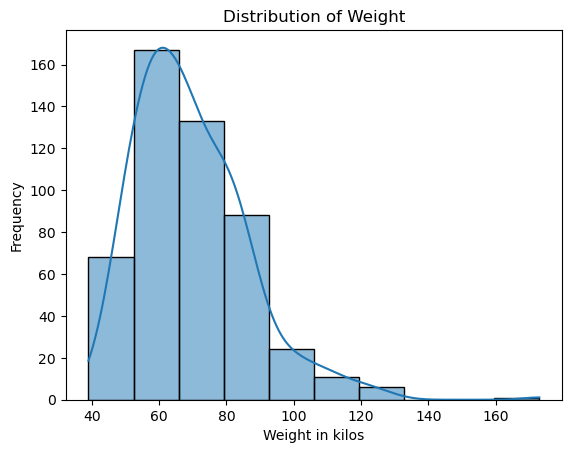

In [21]:
#Graphs of Weight
data=df_raw['Weight']

sns.histplot(data=data, bins=10, kde=True)

plt.title('Distribution of Weight')
plt.xlabel('Weight in kilos')
plt.ylabel('Frequency')
plt.show()

In [22]:
# Checking the minimum value of weight
df_raw['Weight'].min()

39.0

In [23]:
# Checking the maximum value of weight
df_raw['Weight'].max()

173.0

In [24]:
#Range of maximum and minimum
df_raw['Weight'].max() - df['Weight'].min()

134.0

In [25]:
#Variance of Weight
df_raw['Weight'].var()

289.44987563937815

In [26]:
#standard deviation of Weight
df_raw['Weight'].std()

17.01322649115617

In [27]:
# Calculating Q2 of Weight
Q2 = df_raw['Weight'].quantile(0.5)

Q2

67.0

In [28]:
# Calculating Q3 of Weight
Q3 = df_raw['Weight'].quantile(0.75)

Q3

80.0

In [29]:
# Calculating Q1 of Weight
Q1 = df_raw['Weight'].quantile(0.25)

Q1

58.0

In [30]:
# Calculating IQR of Weight
IQR = Q3  - Q1

IQR

22.0

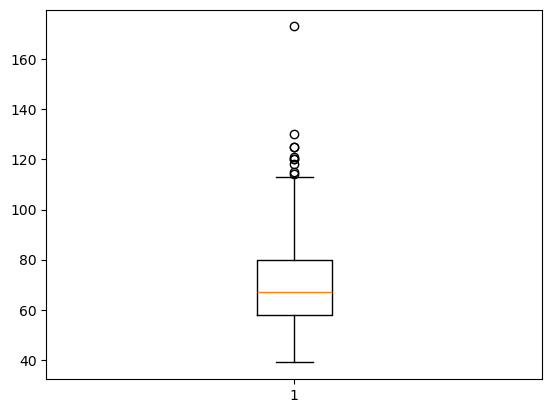

In [31]:
# Checking outliers of Weight using boxplot
plt.boxplot(df_raw['Weight'])

plt.show()

In [32]:
# cheking the skewness of the Weight 
df_raw['Weight'].skew()

1.1935063717508736

In [33]:
# cheking kurt of the Weight 
df_raw['Weight'].kurt()

3.0044812942403003

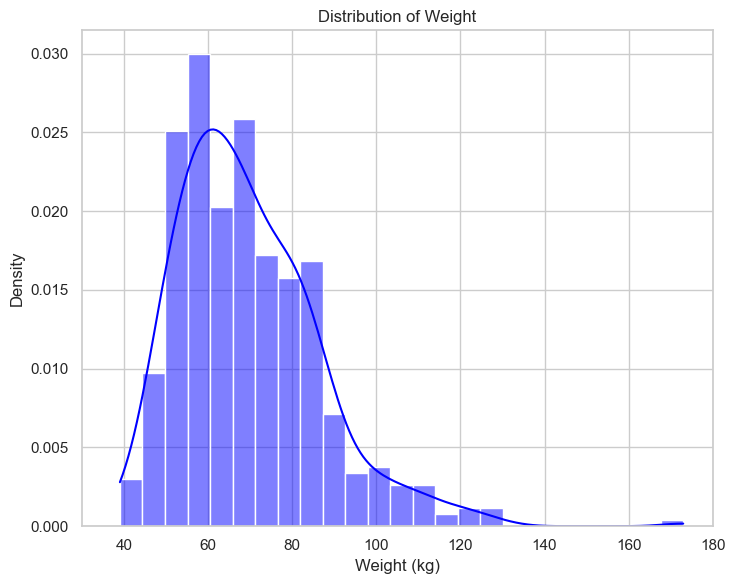

In [36]:
import seaborn as sns
import matplotlib.pyplot as plt

# Set the style of the visualizations
sns.set(style="whitegrid")

# Create a figure with separate plots
plt.figure(figsize=(14, 6))

# Plot for Weight
plt.subplot(1, 2, 1)  # (rows, columns, panel number)
sns.histplot(df_raw['Weight'], bins=25, kde=True, color='blue', stat="density")
plt.title('Distribution of Weight')
plt.xlabel('Weight (kg)')
plt.ylabel('Density')
plt.xlim(30, 180)  # Adjust x-axis limits for better visualization

# Show the plots
plt.tight_layout()
plt.show()

# 2. Use two discrete distributions (Binomial and Poisson) to explain/identify some information about your dataset. You must explain your reasoning and the techniques you have used. Visualize your data and explain what happens with the large samples in these cases. You must work with Python, and your mathematical reasoning must be documented in your report. 

# 3. Use Normal distribution to explain or identify some information about your dataset

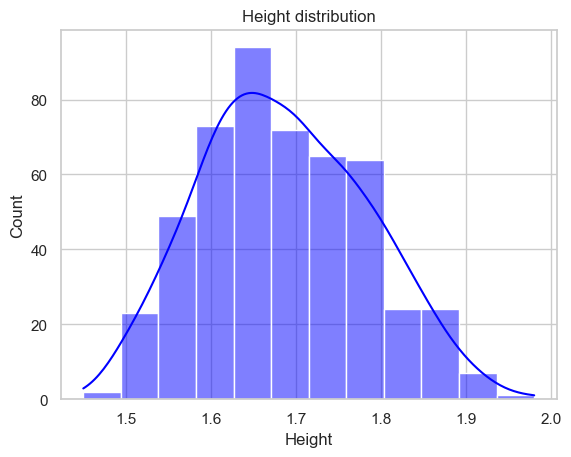

In [41]:
#Inspecting the data visually
x = (df_raw['Height'])
sns.histplot(x, kde=True, bins=12, color='blue')
plt.xlabel('Height')
plt.title('Height distribution')
plt.show()


In [45]:
#Mean and standard deviation in a normal model
mean = x.mean()
std = x.std()
print('Mean:', mean)
print('Standard deviation:', std)

Mean: 1.6863855421686746
Standard deviation: 0.09765349549762498


In [46]:
#The 68-95-99.7 empirical rule
within_1 = ((x >= mean-std) & (x <= mean+std)).mean() * 100
within_2 = ((x >= mean-2*std) & (x <= mean+2*std)).mean() * 100
within_3 = ((x >= mean-3*std) & (x <= mean+3*std)).mean() * 100
 
print(within_1, within_2, within_3)

67.26907630522089 97.38955823293173 99.79919678714859


In [57]:
#Z-score
from scipy import stats
z_scores = stats.zscore(x)
print(z_scores[:498])

0     -0.680491
1     -1.705549
2      1.164615
3      1.164615
4      0.959603
         ...   
493    1.164615
494   -0.167961
495    1.164615
496    0.344568
497   -1.295526
Name: Height, Length: 498, dtype: float64


In [58]:
df_raw['Height'].head()

0    1.62
1    1.52
2    1.80
3    1.80
4    1.78
Name: Height, dtype: float64

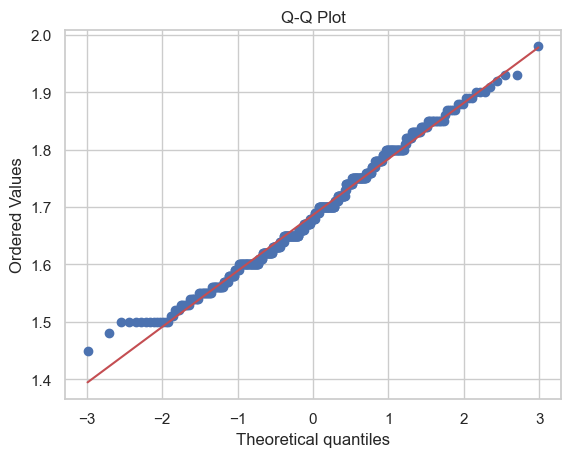

In [53]:
#Q-Q plot
stats.probplot(x, dist='norm', plot=plt)
plt.title('Q-Q Plot')
plt.show()